[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_WaveletIntrusionDetection_Kumari2025.ipynb)

# QSVM with a quantum wavelet-packet front end for IoT intrusion detection: Kumari et al. (2025) step by step

**Paper.** Swati Kumari, Shiva Raj Pokhrel, Swathi Chandrasekhar, Navneet Singh, Hridoy Sankar Dutta, Adnan Anwar, Sutharshan Rajasegarar and Robin Doss,
*"Modeling Wavelet Transformed Quantum Support Vector for Network Intrusion Detection"*, arXiv:2512.01365 (December 2025), submitted to an IEEE journal.
DOI/URL: <https://arxiv.org/abs/2512.01365>.

**What this notebook does.** It rebuilds the paper's whole pipeline on a public copy of the BoT-IoT data and checks the paper's numbers:

1. every IoT flow is turned into a short *quantum circuit* (Algorithm 2: one `RY` rotation per feature, a ladder of `CX`/`H`/`RZ(pi/4)` gates, measurement of all qubits) whose output distribution is the "quantum Haar wavelet" description of the flow;
2. a two-level Haar wavelet-packet transform of that distribution gives four sub-bands, from which the paper's *energy entropy* and *chi-square* behaviour markers are computed;
3. PCA reduces the wavelet vector to 8, 10, 12 or 15 values (one value per qubit), which a `ZZFeatureMap` writes into a quantum state;
4. a quantum-kernel SVM (QSVC) classifies the flow as normal or attack. The noisy runs use a depolarizing-noise model, and a *trainable* kernel (extra `RY` layer tuned by SPSA, Algorithm 3) is compared at three learning rates.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` (default in the config cell) the notebook needs about ten minutes on a CPU runtime (1 seed, 600 flows, 8/10/12/15 qubits; the committed outputs are from this mode); with
`FAST_MODE = False` it runs the larger budgets listed in the config cell (3 seeds, 1,500 flows, 30 small draws; plan on one to three hours). The only download is a slice of one Parquet file from the
Hugging Face Hub (about 120 MB are read, a 10,000-row sample is cached). **Nothing is simulated or invented: every point you see below is a real BoT-IoT flow with its real label.**

**What you get at the end.** Tables I and II of the paper re-computed, the optimisation curves of its Figs. 3-4, a classical baseline on identical inputs, and a claim-by-claim verdict.

## The paper in one page

**Problem.** Tell normal IoT network flows from attack flows (DDoS, DoS, reconnaissance, data theft) with a quantum support-vector machine that still works on noisy (NISQ) hardware.

**Method.** (Fig. 2, Algorithms 1-3)
* *Preprocessing*: numerical features, missing values filled, min-max normalisation to [0, 1].
* *Quantum state preparation / QWPT* (Algorithm 2): each normalised feature `c_i` is written onto qubit `i` with `RY(2 arcsin sqrt(c_i))`; for every level `l = 0 .. n-2` pairs of neighbouring qubits get `CX`, `H` and optionally `RZ(pi/4)`; all qubits are measured and the counts divided by the shots give the transformed feature vector `f_k`. The decomposition goes to **level two** (four sub-bands).
* *Behavioural analysis*: normalised **Shannon entropy** of the sub-band energies (Eq. 16) and a **chi-square** statistic against the benign reference (Eq. 17); both are appended to the PCA-reduced features, "adding only two qubits".
* *Enhanced QSVM*: `ZZFeatureMap` (2 repetitions), `FidelityQuantumKernel` (compute-uncompute), `QSVC`. A *trainable* variant puts `RY(theta_i)` before the feature map and tunes `theta` with SPSA and an SVC loss (`QuantumKernelTrainer`, Algorithm 3).
* *Noise*: depolarizing noise in Qiskit Aer. Runs are "noiseless" or "noisy".
* Eqs. 1-3 (noise-aware weighted hinge loss), Eqs. 12-13 (one-class and composite RBF/quantum kernel) are described but no results are reported for them.

**Data.** Bot-IoT (Cyber Range Lab, UNSW Canberra; 5 attack families). The paper does not give sample sizes, features, split, `C`, noise strengths or seeds. The IoT-23 dataset is mentioned only in the abstract and conclusion (89.67 %).

**Claims that can be checked here.**

| Where | Claim |
|---|---|
| Table I | QSVC accuracy for 8 / 10 / 12 / 15 qubits: noiseless 86.67 / 83.33 / 83.33 / 86.67 %, noisy 83.67 / 76.67 / 76.67 / 76.67 % |
| Table II | Trainable kernel, SPSA perturbation 0.05, 10 iterations, learning rate 0.05 / 0.5 / 1.0: noiseless 90.00 / 93.33 / 96.67 %, noisy 83.33 / 93.33 / 90.00 % |
| Section IV | A classical SVC on identical data reaches only 70 %, the quantum model 96.67 % ("26.67 points quantum advantage") |
| Section II-D | The QWPT circuit reproduces a classical Haar/WPT with mean l2 error below 1e-6 |
| Figs. 3-9 | A moderate learning rate (0.5) gives the most stable loss curve and the smallest noise penalty |
| Abstract | 89.67 % on IoT-23 (cannot be checked here, see below) |

## What follows the paper and what had to be chosen

The paper is silent on most numbers needed to run it. Every row marked *chosen* is also tagged `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | Bot-IoT, size and features not given | Hugging Face mirror `masoltani/bot-iot` (`balanced_dataset.parquet`, 7.5 M flows, 35 flow features). Only the first Parquet row group (1.05 M flows) is read; a pool of up to 2,500 flows per family is cached; each seed draws 50 % normal + 50 % attack (equal shares of DDoS, DoS, Reconnaissance, Theft) |
| Identifier columns | not stated | `stime`, `ltime`, `sport`, `dport`, `seq` dropped (timestamps, ports, running sequence number): chosen |
| Sample size and split | Table II accuracies are multiples of 1/30, the 83.67 % of Table I is 251/300 | 1,500 flows, 300 test flows (FAST: 600 and 150), stratified by family; plus a 30-flow-chunk view of the test accuracy, because Table II looks like a 30-flow test set |
| Normalisation | min-max to [0, 1] | min-max fitted on the training split, test values clipped, then clipped to [0.001, 0.999] before the arcsin |
| Wavelet qubits | one qubit per feature (Algorithm 2) | the 8 features with highest ANOVA F-score on the training split (`SelectKBest`), so the transformed vector has 2^8 = 256 entries: chosen |
| QWPT circuit | `CX`, `H`, optional `RZ(pi/4)`, "each pair at level l" | level `l` acts on pairs `(j, j+1)` for `j = 0 .. n-2-l`, `RZ(pi/4)` included: chosen |
| Measurement | counts / shots | exact outcome probabilities of the same circuit (infinite shots); a shot-sampled check is shown |
| Wavelet-packet step | Haar, level 2, "T = 2^h = 4" sub-bands | orthonormal Haar packet in NumPy on the 256-entry distribution -> 4 x 64 coefficients (checked against a quantum circuit and, where installed, PyWavelets) |
| Behaviour markers | Shannon entropy, chi-square, 2 extra qubits | normalised entropy of the 4 band energies; chi-square of the 4 band fractions against the mean benign profile of the training split (scaled by `SHOTS`), `log1p` applied; they take the last two qubits |
| Qubits | 8 / 10 / 12 / 15 | same: `Q - 2` PCA components + 2 markers |
| Feature map | `ZZFeatureMap`, 2 reps | `zz_feature_map(Q, reps=2, entanglement="linear")` (entanglement not stated) |
| Angle range | not stated | PCA scores min-max scaled to [0, pi] (training split), test clipped |
| Kernel / SVM | `FidelityQuantumKernel`, `QSVC`, `C` not stated | exact statevector fidelity kernel, `SVC(kernel="precomputed", C=1)`; kernel value verified against Qiskit's `FidelityStatevectorKernel` |
| Noise model | "depolarizing noise", strengths not stated | 1-qubit error 0.001, 2-qubit error 0.01 per gate on the compute-uncompute circuit, 1,024 shots per kernel entry; the effect is computed analytically and checked against Aer (Section 8): chosen |
| Trainable kernel | `RY(theta)` + `ZZFeatureMap`, SPSA, SVC loss, perturbation 0.05, learning rate 0.05/0.5/1.0, 10 iterations | same, via `QuantumKernelTrainer`; start `theta = 0`; the trainer sees a small stratified subset of the training flows (loss evaluation is the slow part), the final SVC uses the whole training split; 8 qubits (the paper does not say) |
| Classical baseline | "SVC", 70 % | `SVC` (rbf and linear) and RandomForest on exactly the same angles, and on all 32 flow features |
| Seeds | not stated | 3 seeds (FAST: 1), mean and standard deviation |
| IoT-23 | 89.67 % | not run (no configuration is given) |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, pyarrow.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc huggingface_hub pyarrow "PyWavelets==1.8.0"
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack already present; skipping pip install.")

Qiskit stack already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = True      # True: class demo (1 seed, 600 flows, 8/10/12/15 qubits, about 10 min). False: full budgets (3 seeds, 1,500 flows; one to three hours)
SEED = 42

if FAST_MODE:
    SEEDS        = [42]
    N_TOTAL      = 600          # flows drawn per seed (half normal, half attack)
    N_TEST       = 150
    QUBITS       = [8, 10, 12, 15]  # paper Table I: 8, 10, 12, 15
    N_TRAINER    = 40           # training flows seen by the SPSA loss
else:
    SEEDS        = [42, 43, 44]
    N_TOTAL      = 1500         # full budgets: not part of the committed outputs (the dispatcher's shared CPU needed more than 90 min)
    N_TEST       = 300          # CHOICE: Table I's 83.67 % = 251/300
    QUBITS       = [8, 10, 12, 15]
    N_TRAINER    = 60

N_WAVELET_QUBITS = 8            # CHOICE: features entering the Algorithm-2 circuit (one qubit each) -> 256 outcomes
WPT_LEVEL        = 2            # paper: "maximum decomposition level of two"
FM_REPS          = 2            # paper: ZZFeatureMap with 2 repetitions
ENTANGLEMENT     = "linear"     # CHOICE: not stated in the paper
EPS              = 1e-3         # CHOICE: arcsin inputs clipped to [EPS, 1-EPS] ("clipped away from 0 and 1")
SVC_C            = 1.0          # CHOICE: Qiskit QSVC default
SHOTS            = 1024         # shots per kernel entry on the noisy runs (and in the chi-square pseudo-counts)
P1Q, P2Q         = 0.001, 0.01  # CHOICE: depolarizing error per 1-qubit / 2-qubit gate (paper gives no value)
SCALE_GRID       = [0.25, 0.5, 1.0]   # bandwidth (angle scale) candidates for the validation-tuned QSVC (training data only)
C_GRID           = [1.0, 10.0, 100.0]
VAL_FRACTION     = 0.25

TRAIN_QUBITS     = 8            # CHOICE: qubit count of the trainable kernel (paper does not say)
SPSA_MAXITER     = 10           # paper Table II: iter = 10
SPSA_PERTURBATION= 0.05         # paper Table II: Pr = 0.05
SPSA_LRS         = [0.05, 0.5, 1.0]   # paper Table II: Lr
SMALL_DRAWS      = 8 if FAST_MODE else 30   # repeated paper-sized experiments (about 150 flows, 30 test flows)
N_AER_PAIRS      = 6            # state pairs used to validate the analytic noise model against Aer

POOL_PER_CATEGORY = 2500        # flows cached per traffic family
ROW_GROUP         = 0           # Parquet row group of the Hugging Face file that is read (1,048,576 flows)
HF_REPO, HF_FILE  = "masoltani/bot-iot", "balanced_dataset.parquet"
DATA_DIR = "data"               # cache folder; put botiot_pool.parquet here to skip the download

In [3]:
import os, time, warnings, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel, TrainableFidelityStatevectorKernel
from qiskit_machine_learning.kernels.algorithms import QuantumKernelTrainer
from qiskit_machine_learning.optimizers import SPSA
from qiskit_machine_learning.utils.loss_functions import SVCLoss
warnings.filterwarnings("ignore")

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| FAST_MODE =", FAST_MODE, "| seeds", SEEDS)
os.makedirs("figs", exist_ok=True)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
numpy 2.5.4 | pandas 3.0.6 | FAST_MODE = True | seeds [42]


## 1. The data: real BoT-IoT flows

Bot-IoT (Koroniotis et al., 2019) was recorded in a lab IoT testbed: normal traffic plus DDoS, DoS, reconnaissance (OS fingerprinting, service scans) and information theft
(keylogging, data exfiltration). The Hugging Face mirror `masoltani/bot-iot` is a public, 730 MB Parquet file with 35 flow features, a binary column `attack`, a family column `category` and a
`subcategory` column. We read **one row group** (1,048,576 flows, about 120 MB over the network, nothing is written to disk except a small cache) and keep up to 2,500 flows per family as the pool every seed samples from.

If the Hub is not reachable the notebook stops with a clear message: put `botiot_pool.parquet` (columns of the mirror) into `DATA_DIR` to continue. The file is public, so no token is needed;
a token from your Hugging Face account is only used if one is present (`HF_TOKEN` in the environment or in Colab *Secrets*), which avoids rate limits.

In [4]:
# Hugging Face token: environment variable or Colab Secrets only. It is never printed or written anywhere.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

POOL_PATH = os.path.join(DATA_DIR, "botiot_pool.parquet")
ID_COLS = ["stime", "ltime", "sport", "dport", "seq"]      # CHOICE: timestamps, ports and the running sequence number identify a capture, not behaviour
LABEL_COLS = ["attack", "category", "subcategory"]

def download_pool():
    import pyarrow.parquet as pq
    from huggingface_hub import HfFileSystem
    last = None
    for attempt in range(3):
        try:
            fs = HfFileSystem(token=HF_TOKEN)
            with fs.open(f"datasets/{HF_REPO}/{HF_FILE}", "rb") as f:
                df = pq.ParquetFile(f).read_row_group(ROW_GROUP).to_pandas()
            break
        except Exception as e:                                 # network hiccup: retry
            last = e; time.sleep(5); df = None
    if df is None:
        raise RuntimeError(f"BoT-IoT could not be downloaded from the Hugging Face Hub ({last!r}). "
                           f"Place a Parquet file with the mirror's columns at {POOL_PATH} and run again.")
    parts = [g.sample(n=min(len(g), POOL_PER_CATEGORY), random_state=SEED) for _, g in df.groupby("category")]
    pool = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    return df.shape, pool

t0 = time.perf_counter()
if os.path.exists(POOL_PATH):
    raw = pd.read_parquet(POOL_PATH); raw_shape = None
    print("loaded cached pool", POOL_PATH)
else:
    raw_shape, raw = download_pool()
    raw.to_parquet(POOL_PATH)
    print(f"row group {ROW_GROUP} of {HF_REPO}/{HF_FILE}: {raw_shape[0]:,} flows x {raw_shape[1]} columns; cached a pool of {len(raw):,} flows to {POOL_PATH}")
print(f"pool: {raw.shape}  ({time.perf_counter() - t0:.0f} s)")

loaded cached pool data\botiot_pool.parquet
pool: (12500, 40)  (1 s)


In [5]:
# ---- cleaning (same recipe as the other notebooks of this repository) ----
pool = raw.copy()
pool.columns = [c.strip() for c in pool.columns]
FEATURES = [c for c in pool.columns if c not in ID_COLS + LABEL_COLS]
pool[FEATURES] = pool[FEATURES].apply(pd.to_numeric, errors="coerce")
pool = pool.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)
n_before = len(pool)
pool = pool.drop_duplicates(subset=FEATURES + ["attack"]).reset_index(drop=True)
const = [c for c in FEATURES if pool[c].nunique() <= 1]
FEATURES = [c for c in FEATURES if c not in const]
print(f"dropped {n_before - len(pool)} duplicate flows and {len(const)} constant columns {const}; pool now {pool.shape}")
print(f"{len(FEATURES)} numerical flow features; dropped identifier columns: {ID_COLS}")
ATTACK_CATS = ["DDoS", "DoS", "Reconnaissance", "Theft"]
assert (pool.category.value_counts().reindex(["Normal"] + ATTACK_CATS) >= N_TOTAL // 2).all(), "pool too small for N_TOTAL"
print(pool.category.value_counts().to_string())

dropped 997 duplicate flows and 0 constant columns []; pool now (11503, 40)
32 numerical flow features; dropped identifier columns: ['stime', 'ltime', 'sport', 'dport', 'seq']
category
DoS               2492
DDoS              2454
Reconnaissance    2367
Normal            2207
Theft             1983


## 2. The quantum Haar wavelet-packet front end (Algorithm 2)

For one flow with features `c_1 .. c_n` in [0, 1] the circuit is

```
RY(2 arcsin sqrt(c_i))  on qubit i                       (state preparation, Eq. 14)
for level l = 0 .. n-2:  for j = 0 .. n-2-l:  CX(j, j+1);  H(j);  RZ(pi/4) on j+1
measure all qubits                                       -> 2^n outcome probabilities f_k
```

`f` (256 numbers for 8 qubits) is the "transformed feature vector". The wavelet-packet step then splits it with a Haar filter bank (low-pass `(a+b)/sqrt2`, high-pass `(a-b)/sqrt2`) twice,
giving four sub-bands AA, AD, DA, DD of 64 coefficients. Their energies `E_t` are normalised to `P_t` and give the **normalised entropy** (Eq. 16) and the **chi-square** against the benign profile (Eq. 17).

**Why a separate check?** The paper says the QWPT circuit was validated against a classical Haar transform to below 1e-6. A Haar packet on an *amplitude-encoded* vector is exactly a Hadamard
on the low-order qubits (one per level); the next cell proves this on random vectors and compares it with the NumPy transform used for the features (and with PyWavelets when installed).

In [6]:
def haar_step(x):
    # one orthonormal Haar level on the last axis: low-pass (pairs summed) and high-pass (pairs differenced)
    a, b = x[..., 0::2], x[..., 1::2]
    return (a + b) / np.sqrt(2), (a - b) / np.sqrt(2)

def wpt2(p):
    # two-level Haar wavelet *packet*: both branches are split again -> bands AA, AD, DA, DD, shape (N, 4, len/4)
    A, D = haar_step(np.atleast_2d(p))
    AA, AD = haar_step(A); DA, DD = haar_step(D)
    return np.stack([AA, AD, DA, DD], axis=1)

# ---- validation 1: quantum circuit (amplitude-encoded vector + H on qubits 0 and 1) versus the NumPy packet transform ----
from qiskit.circuit.library import StatePreparation
vec_rng = np.random.default_rng(0)
errs = []
for _ in range(20):
    v = vec_rng.random(256); v /= np.linalg.norm(v)
    qc = QuantumCircuit(8); qc.append(StatePreparation(v), range(8)); qc.h(0); qc.h(1)
    amp = Statevector(qc).data.real
    ref = wpt2(v)[0]                                      # (4, 64) bands AA, AD, DA, DD
    amp_bands = amp.reshape(64, 2, 2)                      # index = 4*m + 2*bit1 + bit0 ; bit0 = first level (A/D), bit1 = second level
    circ_bands = np.stack([amp_bands[:, 0, 0], amp_bands[:, 1, 0], amp_bands[:, 0, 1], amp_bands[:, 1, 1]])
    errs.append(np.linalg.norm(circ_bands - ref))
    E_circ = np.array([(amp_bands[:, 0, 0]**2).sum(), (amp_bands[:, 1, 0]**2).sum(), (amp_bands[:, 0, 1]**2).sum(), (amp_bands[:, 1, 1]**2).sum()])
    assert np.allclose(E_circ, (ref**2).sum(1)) and np.isclose(E_circ.sum(), 1.0)
print(f"mean l2 error, quantum Hadamard circuit vs NumPy Haar packet: {np.mean(errs):.2e}  (paper: below 1e-6)")
QWPT_L2_ERROR = float(np.mean(errs))
try:
    import pywt
    wp = pywt.WaveletPacket(v, "haar", maxlevel=2)
    pw = np.stack([wp[k].data for k in ["aa", "ad", "da", "dd"]])
    print("PyWavelets haar packet vs NumPy (absolute values, sign convention differs):", float(np.abs(np.abs(pw) - np.abs(ref)).max()))
except ImportError:
    print("PyWavelets not installed here (it is pinned in the Colab install cell); the NumPy transform above is the one used throughout.")

mean l2 error, quantum Hadamard circuit vs NumPy Haar packet: 1.39e-12  (paper: below 1e-6)
PyWavelets not installed here (it is pinned in the Colab install cell); the NumPy transform above is the one used throughout.


In [7]:
# ---- the Algorithm-2 circuit with symbolic angles; probabilities are computed with Statevector (= infinite shots) ----
NW = N_WAVELET_QUBITS
theta_in = ParameterVector("t", NW)
def build_qwpt(n=NW, thetas=None):
    qc = QuantumCircuit(n, name="QWPT")
    for i in range(n):
        qc.ry(thetas[i], i)                                   # amplitude encoding of feature i (Eq. 14)
    for l in range(n - 1):
        qc.barrier()
        for j in range(0, n - 1 - l):                         # CHOICE: pairs (j, j+1), j = 0 .. n-2-l, at level l
            qc.cx(j, j + 1); qc.h(j); qc.rz(np.pi / 4, j + 1)
    return qc
qwpt_circ = build_qwpt(NW, theta_in)

def qwpt_probs(A):
    # A: (N, NW) features in (0,1) -> (N, 2^NW) outcome probabilities of the measured circuit
    out = np.empty((len(A), 2**NW))
    for r, a in enumerate(A):
        out[r] = Statevector(qwpt_circ.assign_parameters(2 * np.arcsin(np.sqrt(a)))).probabilities()
    return out

# shot-sampled check of one flow: counts / shots against the exact probabilities
a0 = np.random.default_rng(1).uniform(0.05, 0.95, NW)
p_exact = qwpt_probs(a0[None])[0]
sv0 = Statevector(qwpt_circ.assign_parameters(2 * np.arcsin(np.sqrt(a0))))
cnt = sv0.sample_counts(shots=20000, qargs=range(NW))
p_shots = np.zeros(2**NW)
for b, c in cnt.items(): p_shots[int(b, 2)] = c / 20000
print(f"total-variation distance, 20,000 shots vs exact probabilities: {0.5*np.abs(p_shots - p_exact).sum():.3f} (shot noise only)")

total-variation distance, 20,000 shots vs exact probabilities: 0.041 (shot noise only)


## 3. Sampling, split and every transform fitted on the training split

`prepare(seed)` is the whole classical front end for one seed:

1. draw `N_TOTAL` flows: half normal, half attack (equal shares of the four attack families), then a **stratified** train/test split by family;
2. min-max normalise all flow features (fitted on the training flows; test values clipped);
3. pick the 8 features with the highest F-score (training flows only) and push each flow through the QWPT circuit;
4. two-level Haar packet -> 4 x 64 coefficients, band energies, normalised entropy and chi-square (benign reference = mean band profile of the *training* normal flows).

In [8]:
def make_markers(P_t, ref):
    # P_t: (N,4) band fractions -> normalised Shannon entropy (Eq. 16) and chi-square vs benign profile (Eq. 17)
    H = -(P_t * np.log2(P_t + 1e-12)).sum(1) / np.log2(P_t.shape[1])
    chi2 = (SHOTS * (P_t - ref) ** 2 / ref).sum(1)            # CHOICE: fractions scaled by SHOTS pseudo-counts
    return np.c_[H, np.log1p(chi2)]                           # CHOICE: log1p tames the heavy tail before min-max scaling

def prepare(seed, n_total=None, n_test=None):
    n_total, n_test = n_total or N_TOTAL, n_test or N_TEST
    n_norm, n_att = n_total // 2, n_total // 2 // 4
    parts = [pool[pool.category == "Normal"].sample(n_norm, random_state=seed)]
    parts += [pool[pool.category == c].sample(n_att, random_state=seed) for c in ATTACK_CATS]
    d = pd.concat(parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    X, y, cat = d[FEATURES].to_numpy(float), d["attack"].to_numpy(int), d["category"].to_numpy()
    idx_tr, idx_te = train_test_split(np.arange(len(d)), test_size=n_test, stratify=cat, random_state=seed)
    mm = MinMaxScaler().fit(X[idx_tr])
    Xtr, Xte = mm.transform(X[idx_tr]), np.clip(mm.transform(X[idx_te]), 0, 1)
    ytr, yte, ctr, cte = y[idx_tr], y[idx_te], cat[idx_tr], cat[idx_te]
    sel = SelectKBest(f_classif, k=NW).fit(Xtr, ytr)
    sel_names = [FEATURES[i] for i in sel.get_support(indices=True)]
    Atr = np.clip(sel.transform(Xtr), EPS, 1 - EPS); Ate = np.clip(sel.transform(Xte), EPS, 1 - EPS)
    Ptr, Pte = qwpt_probs(Atr), qwpt_probs(Ate)
    Wtr, Wte = wpt2(Ptr), wpt2(Pte)                           # (N, 4, 64)
    Etr, Ete = (Wtr ** 2).sum(-1), (Wte ** 2).sum(-1)
    Ftr, Fte = Etr / Etr.sum(1, keepdims=True), Ete / Ete.sum(1, keepdims=True)
    ref = Ftr[ytr == 0].mean(0)
    return dict(seed=seed, sel_names=sel_names, Xtr=Xtr, Xte=Xte, Atr=Atr, Ate=Ate, ytr=ytr, yte=yte, ctr=ctr, cte=cte,
                Wtr=Wtr.reshape(len(Wtr), -1), Wte=Wte.reshape(len(Wte), -1), mk_tr=make_markers(Ftr, ref), mk_te=make_markers(Fte, ref),
                bands_tr=Ftr, d=d)

def to_angles(D, Q, kind="qwpt"):
    # kinds: qwpt (paper: Q-2 PCA scores of the wavelet vector + 2 markers), qwpt_nomark (Q PCA scores), raw8 (PCA of the 8 selected raw features), allpca (PCA of all flow features)
    if kind in ("qwpt", "qwpt_nomark"):
        Ftr, Fte = D["Wtr"], D["Wte"]
    elif kind == "raw8":
        Ftr, Fte = D["Atr"], D["Ate"]
    else:
        Ftr, Fte = D["Xtr"], D["Xte"]
    k = Q - 2 if kind == "qwpt" else min(Q, Ftr.shape[1])
    sc = StandardScaler().fit(Ftr)
    pca = PCA(n_components=k, random_state=D["seed"]).fit(sc.transform(Ftr))
    Ztr, Zte = pca.transform(sc.transform(Ftr)), pca.transform(sc.transform(Fte))
    if kind == "qwpt":
        Ztr, Zte = np.c_[Ztr, D["mk_tr"]], np.c_[Zte, D["mk_te"]]
    m2 = MinMaxScaler((0, np.pi)).fit(Ztr)
    return m2.transform(Ztr), np.clip(m2.transform(Zte), 0, np.pi), Ztr, Zte

t0 = time.perf_counter()
DATA = {s: prepare(s) for s in SEEDS}
D0 = DATA[SEEDS[0]]
print(f"prepared {len(SEEDS)} seed(s) in {time.perf_counter() - t0:.0f} s; seed {SEEDS[0]}: train {D0['Xtr'].shape}, test {D0['Xte'].shape}, wavelet vector {D0['Wtr'].shape[1]}")
print("features that enter the QWPT circuit (seed %d):" % SEEDS[0], D0["sel_names"])

prepared 1 seed(s) in 36 s; seed 42: train (450, 32), test (150, 32), wavelet vector 256
features that enter the QWPT circuit (seed 42): ['proto_number', 'mean', 'stddev', 'min', 'max', 'TnP_PerProto', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP']


## Dataset Exploration and Visualisation

Everything below is drawn from the **real BoT-IoT flows** that the model sees. Colours are the ground-truth traffic families (five classes; the binary label `attack` is the union of the four attack families).

pool (all cached flows): (11503, 40) | analysed sample per seed: 600 flows (train 450 / test 150)
flow features (32):
['flgs_number', 'proto_number', 'pkts', 'bytes', 'state_number', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP', 'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP', 'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport', 'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP']

original label column `attack`: {0: 2207, 1: 9296} (0 = normal, 1 = attack)

category counts in the pool:
 category
DoS               2492
DDoS              2454
Reconnaissance    2367
Normal            2207
Theft             1983

subcategory counts in the pool:
 subcategory
Normal               2207
Service_Scan         1907
D-U                  1544
DD-T                 1220
DD-U                 1212
Keylogging 

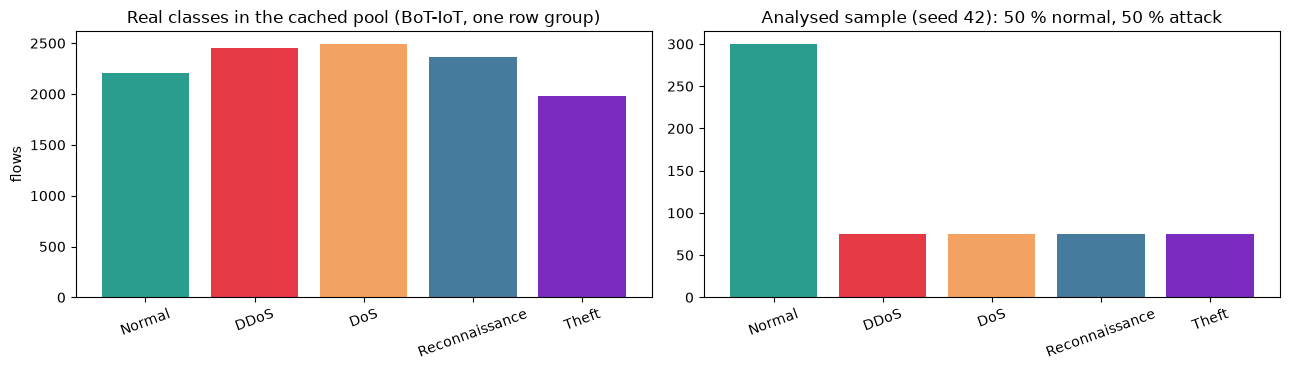

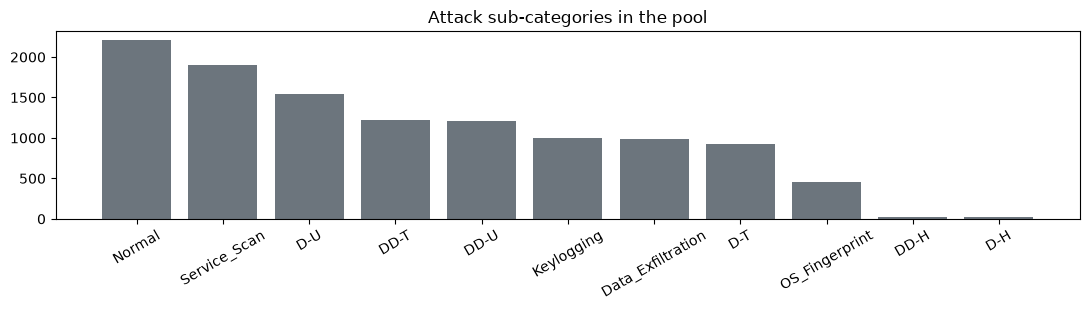

In [9]:
print("pool (all cached flows):", pool.shape, "| analysed sample per seed:", N_TOTAL, "flows (train %d / test %d)" % (len(D0['ytr']), len(D0['yte'])))
print("flow features (%d):" % len(FEATURES)); print(FEATURES)
print("\noriginal label column `attack`:", {int(k): int(v) for k, v in pool.attack.value_counts().sort_index().items()}, "(0 = normal, 1 = attack)")
print("\ncategory counts in the pool:\n", pool.category.value_counts().to_string())
print("\nsubcategory counts in the pool:\n", pool.subcategory.value_counts().to_string())
print("\nanalysed sample (seed %d), category counts:" % SEEDS[0], {k: int(v) for k, v in D0["d"].category.value_counts().items()})
CAT_ORDER = ["Normal"] + ATTACK_CATS
CAT_COLORS = {"Normal": "#2a9d8f", "DDoS": "#e63946", "DoS": "#f4a261", "Reconnaissance": "#457b9d", "Theft": "#7b2cbf"}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
vc = pool.category.value_counts().reindex(CAT_ORDER)
ax[0].bar(CAT_ORDER, vc.values, color=[CAT_COLORS[c] for c in CAT_ORDER]); ax[0].set_title("Real classes in the cached pool (BoT-IoT, one row group)"); ax[0].set_ylabel("flows")
vs = D0["d"].category.value_counts().reindex(CAT_ORDER)
ax[1].bar(CAT_ORDER, vs.values, color=[CAT_COLORS[c] for c in CAT_ORDER]); ax[1].set_title("Analysed sample (seed %d): 50 %% normal, 50 %% attack" % SEEDS[0])
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
sub = pool.subcategory.value_counts()
fig, a = plt.subplots(figsize=(11, 3.2)); a.bar(sub.index, sub.values, color="#6c757d"); a.set_title("Attack sub-categories in the pool"); a.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()

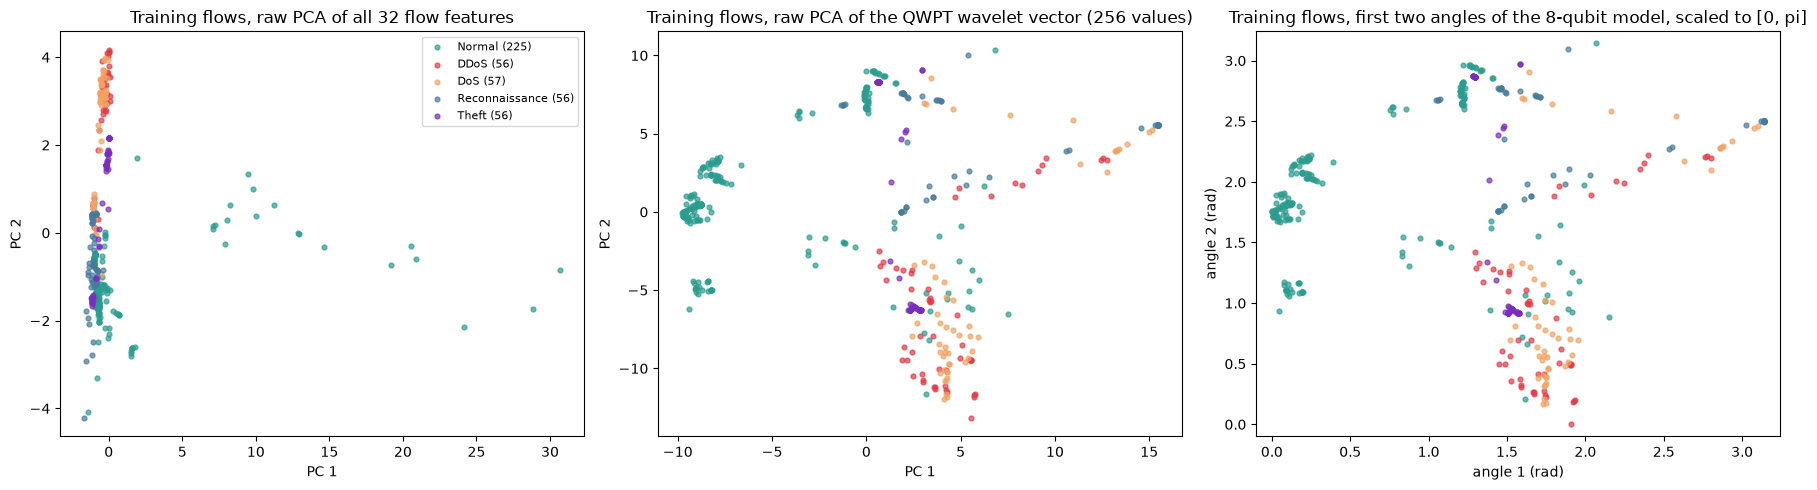

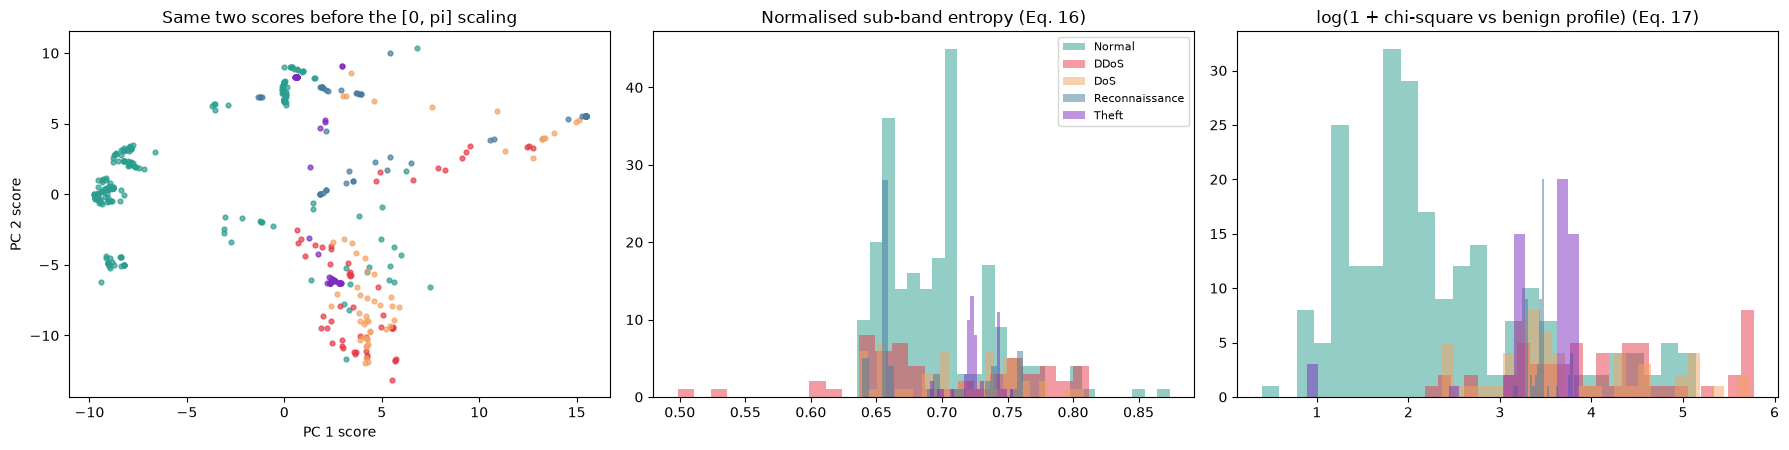

In [10]:
def scatter_by_cat(ax, Z, cats, title, xlabel, ylabel, **kw):
    for c in CAT_ORDER:
        m = cats == c
        ax.scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.7, c=CAT_COLORS[c], label=f"{c} ({m.sum()})", **kw)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# (1) raw flow features: PCA fitted on the training split
p_raw = PCA(2, random_state=SEED).fit(StandardScaler().fit(D0["Xtr"]).transform(D0["Xtr"]))
sc_raw = StandardScaler().fit(D0["Xtr"])
scatter_by_cat(axes[0], p_raw.transform(sc_raw.transform(D0["Xtr"])), D0["ctr"], "Training flows, raw PCA of all %d flow features" % len(FEATURES), "PC 1", "PC 2")
# (2) QWPT wavelet vector: PCA fitted on the training split
sc_w = StandardScaler().fit(D0["Wtr"]); p_w = PCA(2, random_state=SEED).fit(sc_w.transform(D0["Wtr"]))
scatter_by_cat(axes[1], p_w.transform(sc_w.transform(D0["Wtr"])), D0["ctr"], "Training flows, raw PCA of the QWPT wavelet vector (256 values)", "PC 1", "PC 2")
# (3) the two first model inputs as angles in [0, pi] (8-qubit model)
Ztr8, Zte8, Zraw_tr8, Zraw_te8 = to_angles(D0, 8)
scatter_by_cat(axes[2], Ztr8, D0["ctr"], "Training flows, first two angles of the 8-qubit model, scaled to [0, pi]", "angle 1 (rad)", "angle 2 (rad)")
axes[2].set_xlim(-0.1, np.pi + 0.1); axes[2].set_ylim(-0.1, np.pi + 0.1)
axes[0].legend(fontsize=8, loc="best"); plt.tight_layout(); plt.show()

# raw 2-D PCA scores of the model input before scaling, and the behaviour markers by class
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
scatter_by_cat(axes[0], Zraw_tr8, D0["ctr"], "Same two scores before the [0, pi] scaling", "PC 1 score", "PC 2 score")
for c in CAT_ORDER:
    m = D0["ctr"] == c
    axes[1].hist(D0["mk_tr"][m, 0], bins=25, alpha=0.5, color=CAT_COLORS[c], label=c)
    axes[2].hist(D0["mk_tr"][m, 1], bins=25, alpha=0.5, color=CAT_COLORS[c], label=c)
axes[1].set_title("Normalised sub-band entropy (Eq. 16)"); axes[2].set_title("log(1 + chi-square vs benign profile) (Eq. 17)")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. A fast exact simulator for the `ZZFeatureMap` state, checked against Qiskit

Qiskit's `FidelityStatevectorKernel` builds one 2^Q state vector per flow with Python-level gate loops, which takes about 0.3 s per flow at 15 qubits. The `ZZFeatureMap` is simple enough
(`H` on all qubits, then a diagonal phase, repeated twice) to be simulated in a few NumPy lines. The cell below does so, and then **proves the two agree**: states (up to a global phase),
the kernel matrix (`np.allclose`) and the `QSVC` predictions. The `RY(theta)` layer of the trainable kernel is supported through `ry=`.

In [11]:
def _bits(n):
    k = np.arange(2**n)[:, None]
    return ((k >> np.arange(n)) & 1).astype(np.float64)          # (2^n, n); column i = qubit i (little endian, as in Qiskit)

def _hadamard_all(psi, n):
    b = psi.shape[0]
    for i in range(n):
        v = psi.reshape(b, 2**(n - 1 - i), 2, 2**i)
        psi = (np.stack([v[:, :, 0, :] + v[:, :, 1, :], v[:, :, 0, :] - v[:, :, 1, :]], axis=2) / np.sqrt(2)).reshape(b, -1)
    return psi

def zz_states(Z, reps=FM_REPS, ry=None, chunk=64):
    # statevectors of U_ZZ(x)^reps H^n applied to |0..0> (or to RY(ry)|0..0>) for every row of Z; returns (B, 2^n) complex64
    Z = np.atleast_2d(np.asarray(Z, float)); B, n = Z.shape; N = 2**n
    bits = _bits(n)
    xor = (bits[:, :-1] != bits[:, 1:]).astype(float)              # linear entanglement: pairs (i, i+1)
    if ry is None:
        init = np.zeros(N, complex); init[0] = 1
    else:
        c, s = np.cos(np.asarray(ry) / 2), np.sin(np.asarray(ry) / 2)
        init = np.prod(np.where(bits == 1, s, c), axis=1).astype(complex)
    out = np.empty((B, N), np.complex64)
    for a in range(0, B, chunk):
        z = Z[a:a + chunk]
        phase = 2 * z @ bits.T + 2 * ((np.pi - z[:, :-1]) * (np.pi - z[:, 1:])) @ xor.T      # P(2 x_i) and CX P(2 (pi-x_i)(pi-x_j)) CX
        ph = np.exp(1j * phase)
        psi = np.tile(init, (len(z), 1))
        for _ in range(reps):
            psi = _hadamard_all(psi, n) * ph
        out[a:a + chunk] = psi
    return out

def fid_kernel(SA, SB, chunk=256):
    SBH = np.ascontiguousarray(SB.conj().T)
    K = np.empty((len(SA), len(SB)))
    for a in range(0, len(SA), chunk):
        K[a:a + chunk] = np.abs(SA[a:a + chunk] @ SBH) ** 2
    return K

# ---- check 1: states against Qiskit's zz_feature_map (with and without the RY layer) ----
chk = np.random.default_rng(5)
for n in (4, 8, 12):
    fm_chk = zz_feature_map(n, reps=FM_REPS, entanglement=ENTANGLEMENT)
    Zc = chk.uniform(0, np.pi, (5, n)); thc = chk.uniform(-np.pi, np.pi, n)
    S_fast, S_fast_ry = zz_states(Zc), zz_states(Zc, ry=thc)
    for r in range(5):
        s_q = Statevector(fm_chk.assign_parameters(Zc[r])).data
        assert np.isclose(abs(np.vdot(s_q, S_fast[r])), 1, atol=1e-5)
        qc_ry = QuantumCircuit(n)
        for i in range(n): qc_ry.ry(thc[i], i)
        qc_ry.compose(fm_chk.assign_parameters(Zc[r]), inplace=True)
        assert np.isclose(abs(np.vdot(Statevector(qc_ry).data, S_fast_ry[r])), 1, atol=1e-5)
print("fast simulator == Qiskit statevectors (overlap 1 up to a global phase), with and without the RY layer")

# ---- check 2: kernel matrix against FidelityStatevectorKernel, and QSVC predictions ----
Ztr8, Zte8, _, _ = to_angles(D0, 8)
sub_tr, sub_te = Ztr8[:60], Zte8[:30]
fm8 = zz_feature_map(8, reps=FM_REPS, entanglement=ENTANGLEMENT)
qk = FidelityStatevectorKernel(feature_map=fm8)
K_q_tr = qk.evaluate(sub_tr); K_q_te = qk.evaluate(sub_te, sub_tr)
S_a, S_b = zz_states(sub_tr), zz_states(sub_te)
K_f_tr, K_f_te = fid_kernel(S_a, S_a), fid_kernel(S_b, S_a)
assert np.allclose(K_q_tr, K_f_tr, atol=1e-5) and np.allclose(K_q_te, K_f_te, atol=1e-5)
y_sub = D0["ytr"][:60]
qsvc = QSVC(quantum_kernel=qk, C=SVC_C).fit(sub_tr, y_sub)
pred_q = qsvc.predict(sub_te); pred_f = SVC(kernel="precomputed", C=SVC_C).fit(K_f_tr, y_sub).predict(K_f_te)
print(f"max |K_qiskit - K_fast| = {max(np.abs(K_q_tr-K_f_tr).max(), np.abs(K_q_te-K_f_te).max()):.1e}; QSVC(FidelityStatevectorKernel) and SVC(precomputed fast kernel) give identical predictions: {bool((pred_q == pred_f).all())}")
assert (pred_q == pred_f).all()

fast simulator == Qiskit statevectors (overlap 1 up to a global phase), with and without the RY layer


max |K_qiskit - K_fast| = 1.3e-06; QSVC(FidelityStatevectorKernel) and SVC(precomputed fast kernel) give identical predictions: True


## Quantum Circuit Architecture

Three distinct gate-based circuits are executed in this notebook. All three are drawn from the objects that are really simulated (symbolic parameters, i.e. before a flow is bound).

1. **QWPT circuit** (Algorithm 2): `RY` state preparation, CX/H/RZ ladder, measurement. 8 qubits.
2. **QSVC feature-map circuit** (Algorithm 1, last procedure): `zz_feature_map` with 2 repetitions; its state `|phi(x)>` enters the fidelity kernel `K(x,y) = |<phi(x)|phi(y)>|^2` (Eq. 8). The kernel is evaluated as compute-uncompute, `U(x)^+ U(y)` followed by the probability of `|0..0>`, which is the circuit whose depth and gate counts matter for noise (Section 8).
3. **Trainable-kernel circuit** (Algorithm 3): a layer `RY(theta_i)` followed by the same `zz_feature_map`; `theta` is optimised by SPSA.

Assumptions where the paper omits details: linear entanglement for the `ZZFeatureMap`; `RY` of the trainable layer acts *before* the feature map; the QWPT ladder acts on pairs `(j, j+1)`, `j = 0 .. n-2-l` at level `l`.

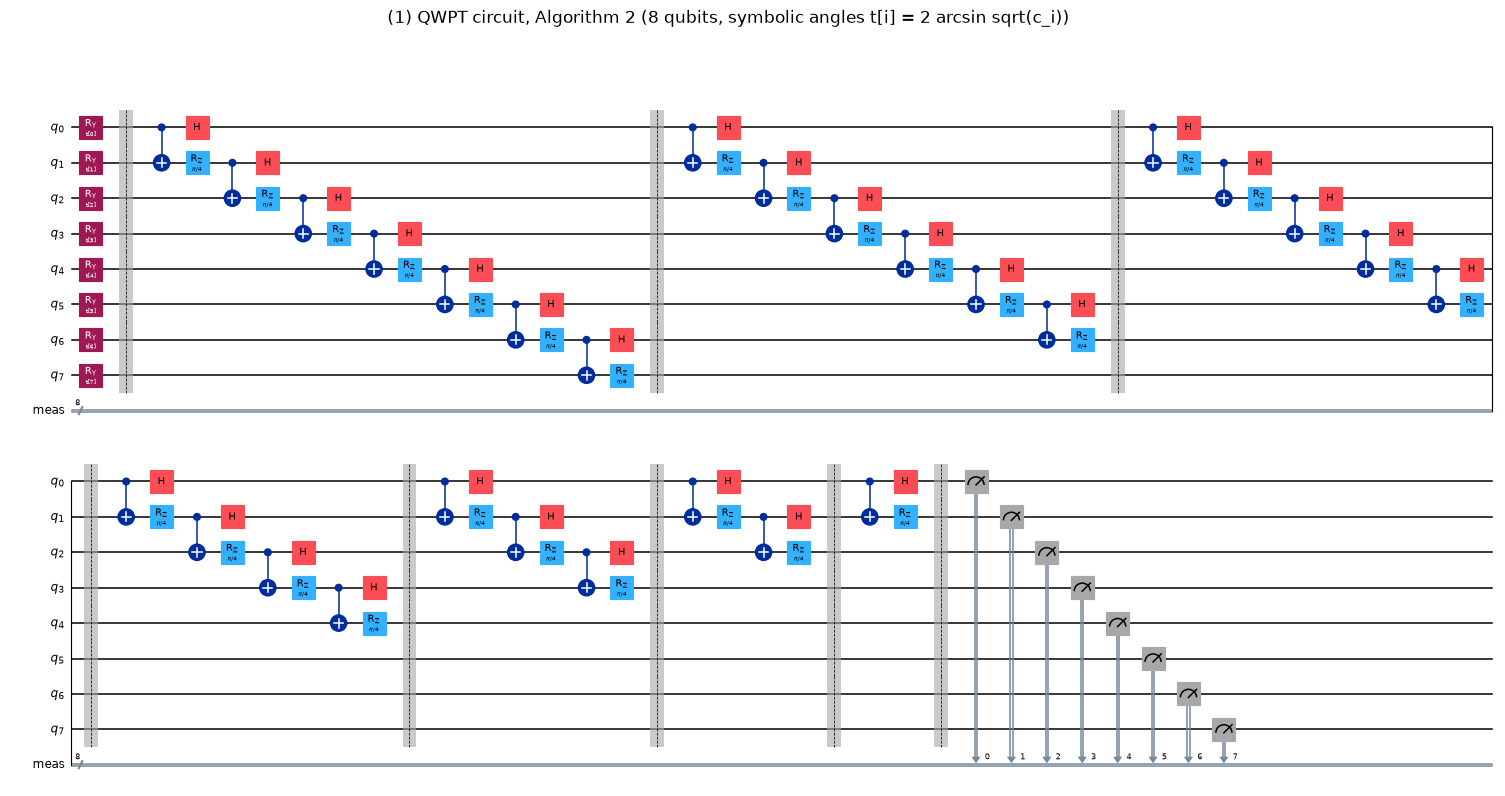

QWPT circuit: 8 qubits, depth 58, 8 input parameters, 0 trainable parameters, gates {'cx': 28, 'h': 28, 'rz': 28, 'ry': 8, 'barrier': 7}


In [12]:
qwpt_meas = qwpt_circ.copy(); qwpt_meas.measure_all()
from IPython.display import display
fig = qwpt_meas.draw("mpl", fold=40, scale=0.55); fig.suptitle("(1) QWPT circuit, Algorithm 2 (8 qubits, symbolic angles t[i] = 2 arcsin sqrt(c_i))"); display(fig)
print(f"QWPT circuit: {qwpt_meas.num_qubits} qubits, depth {qwpt_meas.depth()}, {qwpt_circ.num_parameters} input parameters, 0 trainable parameters, gates {dict(qwpt_circ.count_ops())}")

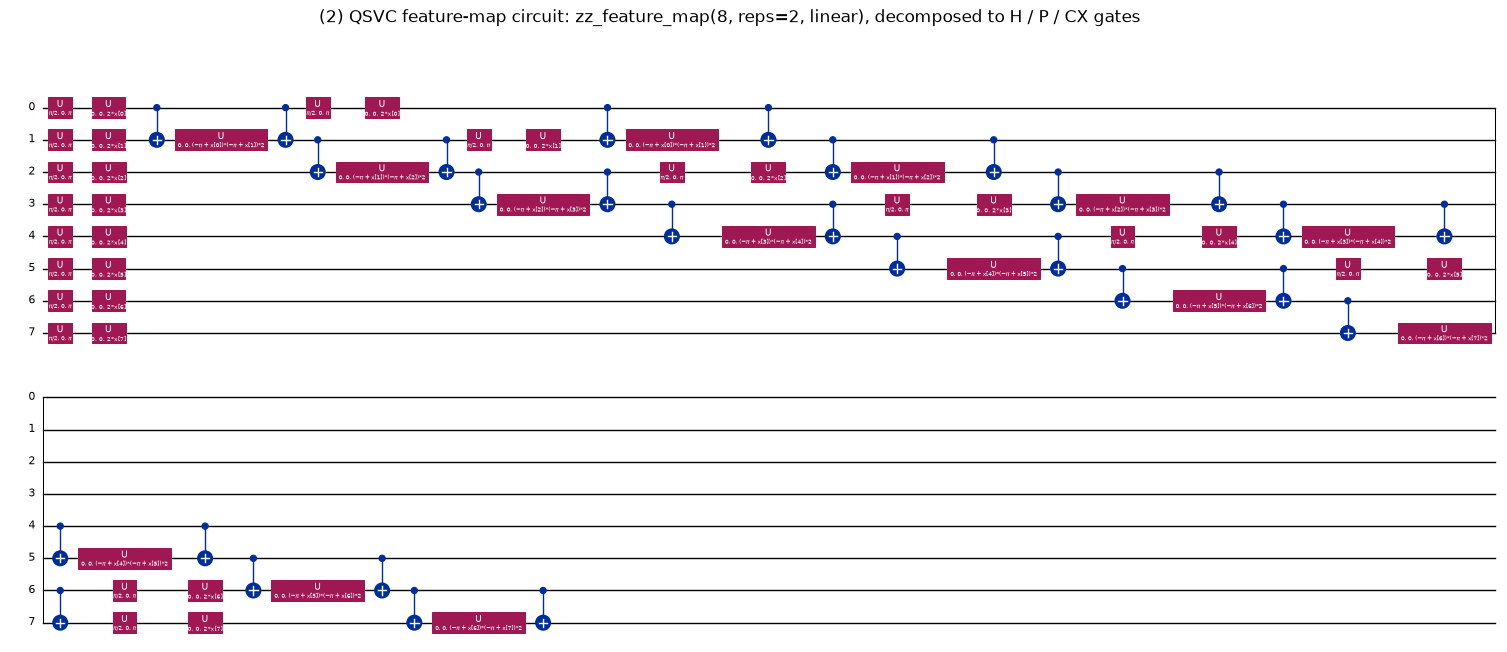

ZZ feature map (8 qubits): depth 31, 8 data parameters, 0 trainable parameters, gates {'u': 46, 'cx': 28}


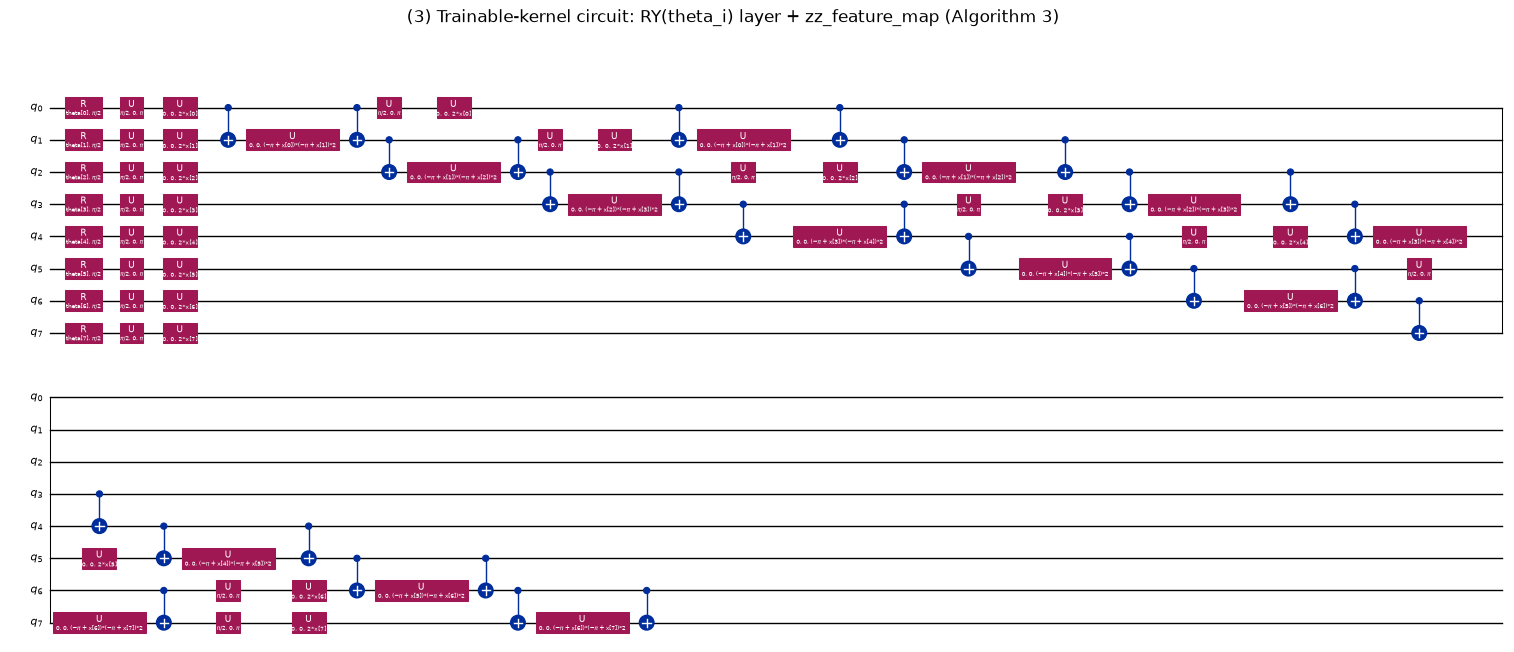

trainable kernel circuit: 8 qubits, depth 32, 8 trainable + 8 data parameters


       qubits  depth  n_2q  n_1q  depolarizing_weight
            8     70    56   156             0.512710
           10     82    72   196             0.601370
           12     94    88   236             0.673899
           15    112   112   296             0.758717
8 (trainable)     80    56   236             0.550193


In [13]:
FM_Q = TRAIN_QUBITS
fm_draw = zz_feature_map(FM_Q, reps=FM_REPS, entanglement=ENTANGLEMENT)
fig = fm_draw.decompose().draw("mpl", fold=45, scale=0.5); fig.suptitle("(2) QSVC feature-map circuit: zz_feature_map(8, reps=2, linear), decomposed to H / P / CX gates"); display(fig)
print(f"ZZ feature map (8 qubits): depth {fm_draw.decompose().depth()}, {fm_draw.num_parameters} data parameters, 0 trainable parameters, gates {dict(fm_draw.decompose().count_ops())}")

theta_tr = ParameterVector("theta", FM_Q)
trainable_circ = QuantumCircuit(FM_Q)
for i in range(FM_Q): trainable_circ.ry(theta_tr[i], i)
trainable_circ.compose(fm_draw, inplace=True)
fig = trainable_circ.decompose().draw("mpl", fold=45, scale=0.5); fig.suptitle("(3) Trainable-kernel circuit: RY(theta_i) layer + zz_feature_map (Algorithm 3)"); display(fig)
print(f"trainable kernel circuit: {trainable_circ.num_qubits} qubits, depth {trainable_circ.decompose().depth()}, {len(theta_tr)} trainable + {fm_draw.num_parameters} data parameters")

# compute-uncompute kernel circuit size per qubit count (needed for the noise model)
BASIS = ["rz", "sx", "x", "cx"]
def cu_gate_counts(n, trainable=False):
    a, b, th = ParameterVector("a", n), ParameterVector("b", n), ParameterVector("th", n)
    def U(vec):
        qc = QuantumCircuit(n)
        if trainable:
            for i in range(n): qc.ry(th[i], i)
        qc.compose(zz_feature_map(n, reps=FM_REPS, entanglement=ENTANGLEMENT).assign_parameters(list(vec)), inplace=True)
        return qc
    cu = U(a).compose(U(b).inverse())
    tc = transpile(cu, basis_gates=BASIS, optimization_level=0)
    ops = tc.count_ops()
    return dict(qubits=n, depth=tc.depth(), n_2q=ops.get("cx", 0), n_1q=sum(v for k, v in ops.items() if k != "cx"))

GATES = {n: cu_gate_counts(n) for n in sorted(set(QUBITS + [TRAIN_QUBITS]))}
GATES_TR = cu_gate_counts(TRAIN_QUBITS, trainable=True)
def lam_of(g): return 1 - (1 - P1Q) ** g["n_1q"] * (1 - P2Q) ** g["n_2q"]
print(pd.DataFrame([dict(g, depolarizing_weight=lam_of(g)) for g in list(GATES.values()) + [dict(GATES_TR, qubits="8 (trainable)")]]).to_string(index=False))

## 5. Metrics, classical baselines and the noise model

**Metrics** are accuracy, precision, recall and F1 with *attack* as the positive class.

**Classical baselines** use exactly the same inputs as the quantum model (the same angle matrix): an RBF-SVC and a linear SVC (`C=1`) and a random forest, plus the same models on all flow
features. The paper reports only "the classic SVC baseline achieves only 70 %".

**Noise.** The paper simulates depolarizing noise in Qiskit Aer, whose density-matrix simulation of the Q-qubit compute-uncompute circuit needs 4^Q complex numbers (about 1 GB at 13 qubits, 16 GB at 15 qubits), so an exact reference is only possible up to roughly 12 qubits. For a circuit with `n1`
single-qubit and `n2` two-qubit gates, each depolarizing with probability `p`, the probability of reading `|0..0>` is, as a first approximation (Section 8 measures how good it is),

`P(0..0) = (1 - lam) K + lam / 2^Q`, with `lam = 1 - (1-p1)^n1 (1-p2)^n2`

i.e. the ideal kernel value `K` is damped and mixed with the uniform distribution; every kernel entry is then estimated from `SHOTS` samples (binomial noise), the diagonal is set to 1 and the
training kernel is projected onto positive semi-definite matrices, which is what Qiskit's `FidelityQuantumKernel` does. Section 8 compares this formula with Aer.

In [14]:
def metrics(y, pred):
    return dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0))

def noisy_kernel(K, lam, nq, rng_, symmetric):
    p = np.clip((1 - lam) * K + lam / 2**nq, 0, 1)
    if symmetric:
        iu = np.triu_indices_from(p, 1)
        v = rng_.binomial(SHOTS, p[iu]) / SHOTS
        Kn = np.eye(len(p)); Kn[iu] = v; Kn.T[iu] = v
        w, V = np.linalg.eigh(Kn); w = np.clip(w, 0, None)           # enforce PSD as FidelityQuantumKernel does
        return (V * w) @ V.T
    return rng_.binomial(SHOTS, p) / SHOTS

def chunk_accuracy(y, pred, size=30):
    # mean and standard deviation of the accuracy over disjoint 30-flow chunks of the test set (Table II of the paper looks like a 30-flow test set)
    a = [accuracy_score(y[i:i + size], pred[i:i + size]) for i in range(0, len(y) - size + 1, size)]
    return float(np.mean(a)), float(np.std(a))

def classical_baselines(Ztr, ytr, Zte, yte, seed):
    r = {}
    r["SVC rbf"] = metrics(yte, SVC(C=1.0).fit(Ztr, ytr).predict(Zte))
    r["SVC linear"] = metrics(yte, SVC(kernel="linear", C=1.0).fit(Ztr, ytr).predict(Zte))
    r["RandomForest"] = metrics(yte, RandomForestClassifier(200, random_state=seed).fit(Ztr, ytr).predict(Zte))
    return r

print("helpers defined")

helpers defined


## 6. Table I: QSVC accuracy against the number of qubits, noiseless and noisy

For every seed and every qubit count: build the angles (`Q-2` PCA scores + 2 behaviour markers), the exact fidelity kernel, fit `SVC(kernel="precomputed")`, predict the test flows. The noisy run
replaces the kernel by its noisy estimate (previous section). `Q = 8` additionally gets a **validation-tuned bandwidth**: angle scale and `C` are chosen on a validation part of the training split only.

In [15]:
TABLE1, BASE, KEEP = [], [], {}
t_all = time.perf_counter()
for seed in SEEDS:
    D = DATA[seed]; rng_n = np.random.default_rng(seed + 1000)
    ytr, yte = D["ytr"], D["yte"]
    for Q in QUBITS:
        t0 = time.perf_counter()
        Ztr, Zte, _, _ = to_angles(D, Q)
        S_tr, S_te = zz_states(Ztr), zz_states(Zte)
        Ktr, Kte = fid_kernel(S_tr, S_tr), fid_kernel(S_te, S_tr)
        del S_tr, S_te
        pred = SVC(kernel="precomputed", C=SVC_C).fit(Ktr, ytr).predict(Kte)
        lam = lam_of(GATES[Q])
        Ktr_n, Kte_n = noisy_kernel(Ktr, lam, Q, rng_n, True), noisy_kernel(Kte, lam, Q, rng_n, False)
        pred_n = SVC(kernel="precomputed", C=SVC_C).fit(Ktr_n, ytr).predict(Kte_n)
        m, mn = metrics(yte, pred), metrics(yte, pred_n)
        row = dict(seed=seed, qubits=Q, noiseless=100 * m["acc"], noisy=100 * mn["acc"], f1_noiseless=m["f1"], f1_noisy=mn["f1"], lam=lam,
                   chunk30_sd_noiseless=100 * chunk_accuracy(yte, pred)[1], chunk30_sd_noisy=100 * chunk_accuracy(yte, pred_n)[1], seconds=time.perf_counter() - t0,
                   kernel_offdiag_mean=float(Ktr[np.triu_indices_from(Ktr, 1)].mean()))
        base = classical_baselines(Ztr, ytr, Zte, yte, seed)
        for k, v in base.items(): row["acc_" + k.replace(" ", "_")] = 100 * v["acc"]
        TABLE1.append(row)
        if seed == SEEDS[0] and Q == QUBITS[0]:
            KEEP.update(pred=pred, pred_noisy=pred_n, yte=yte, cte=D["cte"], Ktr=Ktr)
        print(f"seed {seed} | {Q:2d} qubits | QSVC noiseless {100*m['acc']:.2f} % noisy {100*mn['acc']:.2f} % (lam {lam:.2f}) | SVC rbf {row['acc_SVC_rbf']:.2f} % RF {row['acc_RandomForest']:.2f} % | {row['seconds']:.0f} s")
        del Ktr, Kte, Ktr_n, Kte_n
T1 = pd.DataFrame(TABLE1)
print(f"total {time.perf_counter() - t_all:.0f} s")

seed 42 |  8 qubits | QSVC noiseless 96.67 % noisy 96.00 % (lam 0.51) | SVC rbf 97.33 % RF 99.33 % | 10 s


seed 42 | 10 qubits | QSVC noiseless 97.33 % noisy 96.67 % (lam 0.60) | SVC rbf 97.33 % RF 99.33 % | 14 s


seed 42 | 12 qubits | QSVC noiseless 96.00 % noisy 95.33 % (lam 0.67) | SVC rbf 98.67 % RF 99.33 % | 41 s


seed 42 | 15 qubits | QSVC noiseless 94.67 % noisy 94.67 % (lam 0.76) | SVC rbf 98.67 % RF 100.00 % | 306 s
total 388 s


In [16]:
# classical models on all flow features and on the 8 raw selected features, same split (for context)
ALLF = []
for seed in SEEDS:
    D = DATA[seed]
    for name, (a, b) in {"all 32 flow features": (D["Xtr"], D["Xte"]), "8 selected raw features": (D["Atr"], D["Ate"])}.items():
        r = classical_baselines(a, D["ytr"], b, D["yte"], seed)
        for k, v in r.items(): ALLF.append(dict(seed=seed, inputs=name, model=k, acc=100 * v["acc"]))
ALLF = pd.DataFrame(ALLF)
summ = T1.groupby("qubits").agg(**{c: (c, "mean") for c in ["noiseless", "noisy", "chunk30_sd_noiseless", "chunk30_sd_noisy", "acc_SVC_rbf", "acc_SVC_linear", "acc_RandomForest", "lam"]})
summ_sd = T1.groupby("qubits")[["noiseless", "noisy"]].std().fillna(0).add_suffix("_std")
print("Table I re-computed (mean over seeds %s, test accuracy in %%):" % SEEDS); print(pd.concat([summ, summ_sd], axis=1).round(2).to_string())
print("\nclassical models on other inputs (mean over seeds, %):"); print(ALLF.groupby(["inputs", "model"]).acc.mean().round(2).to_string())

Table I re-computed (mean over seeds [42], test accuracy in %):
        noiseless  noisy  chunk30_sd_noiseless  chunk30_sd_noisy  acc_SVC_rbf  acc_SVC_linear  acc_RandomForest   lam  noiseless_std  noisy_std
qubits                                                                                                                                         
8           96.67  96.00                  2.98              3.27        97.33           94.00             99.33  0.51            0.0        0.0
10          97.33  96.67                  2.49              2.98        97.33           94.00             99.33  0.60            0.0        0.0
12          96.00  95.33                  3.89              2.67        98.67           96.67             99.33  0.67            0.0        0.0
15          94.67  94.67                  3.40              3.40        98.67           97.33            100.00  0.76            0.0        0.0

classical models on other inputs (mean over seeds, %):
inputs          

In [17]:
# validation-tuned bandwidth for the 8-qubit QSVC (angle scale and C chosen on a validation split of the TRAINING flows only)
TUNED = []
for seed in SEEDS:
    D = DATA[seed]; ytr, yte = D["ytr"], D["yte"]
    Ztr, Zte, _, _ = to_angles(D, 8)
    itr, iva = train_test_split(np.arange(len(ytr)), test_size=VAL_FRACTION, stratify=D["ctr"], random_state=seed)
    best = (-1, None, None)
    for sc_ in SCALE_GRID:
        S = zz_states(sc_ * Ztr); K = fid_kernel(S, S)
        for C in C_GRID:
            acc = SVC(kernel="precomputed", C=C).fit(K[np.ix_(itr, itr)], ytr[itr]).score(K[np.ix_(iva, itr)], ytr[iva])
            if acc > best[0]: best = (acc, sc_, C)
    _, sc_, C = best
    S_tr, S_te = zz_states(sc_ * Ztr), zz_states(sc_ * Zte)
    pred = SVC(kernel="precomputed", C=C).fit(fid_kernel(S_tr, S_tr), ytr).predict(fid_kernel(S_te, S_tr))
    TUNED.append(dict(seed=seed, val_acc=100 * best[0], scale=sc_, C=C, test_acc=100 * accuracy_score(yte, pred)))
TUNED = pd.DataFrame(TUNED); print("validation-tuned 8-qubit QSVC:"); print(TUNED.round(2).to_string(index=False))

validation-tuned 8-qubit QSVC:
 seed  val_acc  scale   C  test_acc
   42    97.35   0.25 1.0     97.33


## 7. Ablation: what does the wavelet front end add?

Same 8-qubit QSVC and the same classical SVC, fed with (a) the paper's inputs (6 wavelet PCA scores + 2 markers), (b) 8 wavelet PCA scores without markers, (c) PCA of the 8 selected raw
features (no quantum wavelet step), (d) PCA of all flow features.

In [18]:
ABL = []
for seed in SEEDS:
    D = DATA[seed]; ytr, yte = D["ytr"], D["yte"]
    for kind in ["qwpt", "qwpt_nomark", "raw8", "allpca"]:
        Ztr, Zte, _, _ = to_angles(D, 8, kind)
        S_tr, S_te = zz_states(Ztr), zz_states(Zte)
        pq_ = SVC(kernel="precomputed", C=SVC_C).fit(fid_kernel(S_tr, S_tr), ytr).predict(fid_kernel(S_te, S_tr))
        ps_ = SVC(C=1.0).fit(Ztr, ytr).predict(Zte)
        ABL.append(dict(seed=seed, inputs=kind, QSVC=100 * accuracy_score(yte, pq_), SVC_rbf=100 * accuracy_score(yte, ps_)))
ABL = pd.DataFrame(ABL)
print("ablation, 8 qubits, noiseless, mean test accuracy over seeds (%):"); print(ABL.groupby("inputs")[["QSVC", "SVC_rbf"]].mean().round(2).to_string())

ablation, 8 qubits, noiseless, mean test accuracy over seeds (%):
              QSVC  SVC_rbf
inputs                     
allpca       95.33    93.33
qwpt         96.67    97.33
qwpt_nomark  97.33    97.33
raw8         96.00    99.33


## 7b. A paper-sized experiment: about 150 flows, 30 test flows, many draws

The accuracies of the paper's Table II are multiples of 1/30, which suggests a test set of 30 flows (and a training set of roughly 120). The cell below repeats the 8-qubit QSVC and the classical models on many independent
draws of that size, to show how much a single 30-flow number moves by chance alone.

8 draws of 117 train / 30 test flows (57 s); test accuracy (%):
               mean   std    min     max
QSVC          93.75  4.15  86.67  100.00
QSVC_noisy    92.50  6.11  80.00  100.00
SVC rbf       95.42  3.05  90.00  100.00
SVC linear    92.92  5.18  83.33   96.67
RandomForest  96.67  2.52  93.33  100.00


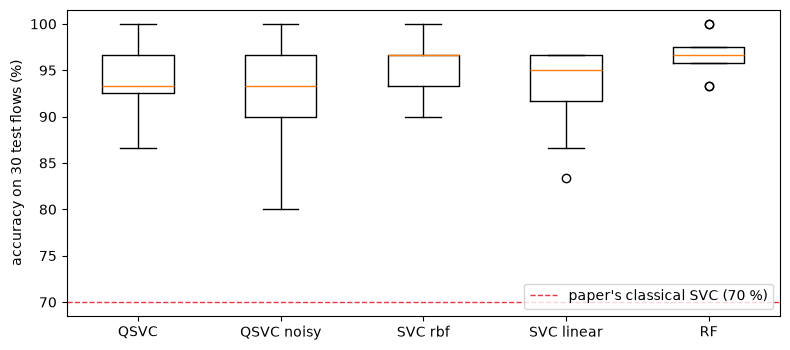

In [19]:
SMALL = []
t0 = time.perf_counter()
for r in range(SMALL_DRAWS):
    D = prepare(1000 + r, n_total=150, n_test=30); rng_n = np.random.default_rng(3000 + r)
    ytr, yte = D["ytr"], D["yte"]
    Ztr, Zte, _, _ = to_angles(D, 8)
    S_tr, S_te = zz_states(Ztr), zz_states(Zte)
    Ktr, Kte = fid_kernel(S_tr, S_tr), fid_kernel(S_te, S_tr)
    lam = lam_of(GATES[8])
    pred = SVC(kernel="precomputed", C=SVC_C).fit(Ktr, ytr).predict(Kte)
    pred_n = SVC(kernel="precomputed", C=SVC_C).fit(noisy_kernel(Ktr, lam, 8, rng_n, True), ytr).predict(noisy_kernel(Kte, lam, 8, rng_n, False))
    row = dict(draw=r, n_train=len(ytr), n_test=len(yte), QSVC=100 * accuracy_score(yte, pred), QSVC_noisy=100 * accuracy_score(yte, pred_n))
    for k, v in classical_baselines(Ztr, ytr, Zte, yte, 1000 + r).items(): row[k] = 100 * v["acc"]
    SMALL.append(row)
SMALL = pd.DataFrame(SMALL)
print(f"{SMALL_DRAWS} draws of {SMALL.n_train[0]} train / {SMALL.n_test[0]} test flows ({time.perf_counter() - t0:.0f} s); test accuracy (%):")
print(pd.DataFrame({"mean": SMALL.iloc[:, 3:].mean(), "std": SMALL.iloc[:, 3:].std(), "min": SMALL.iloc[:, 3:].min(), "max": SMALL.iloc[:, 3:].max()}).round(2).to_string())
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.boxplot([SMALL[c] for c in ["QSVC", "QSVC_noisy", "SVC rbf", "SVC linear", "RandomForest"]]); ax.set_xticklabels(["QSVC", "QSVC noisy", "SVC rbf", "SVC linear", "RF"])
ax.axhline(70, color="#e63946", ls="--", lw=1, label="paper's classical SVC (70 %)"); ax.set_ylabel("accuracy on 30 test flows (%)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 8. Does the analytic noise model match Aer?

Aer's `density_matrix` method applies the depolarizing channel exactly. A density matrix of the `Q`-qubit compute-uncompute circuit needs 4^Q complex numbers (about 1 GB at 13 qubits, 16 GB at 15), so the exact check is limited to modest `Q`
(4, 6 and 8 qubits here). For random pairs of angle vectors the cell compares: the ideal kernel `K`, the Aer probability of `|0..0>` with depolarizing noise (`p1`, `p2`
from the config cell on all gates of the transpiled circuit), and the formula of Section 5.

 qubits  K_ideal  aer_noisy  formula    lam
      4   0.0501     0.0528   0.0535 0.2718
      4   0.1010     0.0971   0.0905 0.2718
      4   0.0100     0.0278   0.0243 0.2718
      4   0.0106     0.0193   0.0247 0.2718
      6   0.0030     0.0060   0.0081 0.4043
      6   0.0498     0.0407   0.0360 0.4043
      6   0.0227     0.0208   0.0198 0.4043
      6   0.0103     0.0112   0.0125 0.4043
      8   0.0001     0.0017   0.0020 0.5127
      8   0.0027     0.0037   0.0033 0.5127
      8   0.0474     0.0332   0.0251 0.5127
      8   0.0077     0.0078   0.0058 0.5127
mean |Aer - formula| = 0.0035 versus mean |Aer - ideal K| = 0.0046 over 18 pairs


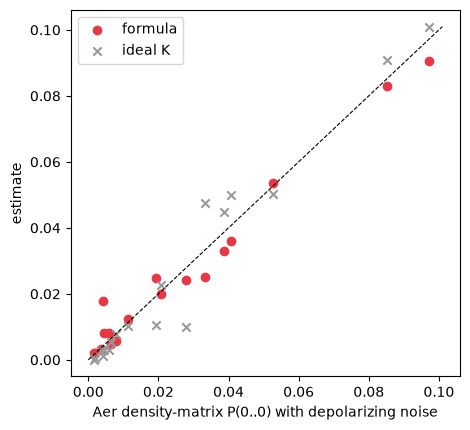

In [20]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
nm = NoiseModel()
nm.add_all_qubit_quantum_error(depolarizing_error(P1Q, 1), ["rz", "sx", "x"])
nm.add_all_qubit_quantum_error(depolarizing_error(P2Q, 2), ["cx"])
sim = AerSimulator(method="density_matrix", noise_model=nm)
v_rng = np.random.default_rng(11); rows = []
for n in (4, 6, 8):
    fm_n = zz_feature_map(n, reps=FM_REPS, entanglement=ENTANGLEMENT)
    for _ in range(N_AER_PAIRS):
        a, b = v_rng.uniform(0, np.pi, n), v_rng.uniform(0, np.pi, n)
        cu = fm_n.assign_parameters(a).compose(fm_n.assign_parameters(b).inverse())
        tc = transpile(cu, basis_gates=BASIS, optimization_level=0)
        ops = tc.count_ops(); n2 = ops.get("cx", 0); n1 = sum(v for k, v in ops.items() if k != "cx")
        tc.save_probabilities_dict()
        p0 = sim.run(tc).result().data()["probabilities"].get(0, 0.0)
        K = abs(np.vdot(Statevector(fm_n.assign_parameters(a)).data, Statevector(fm_n.assign_parameters(b)).data)) ** 2
        lam = 1 - (1 - P1Q) ** n1 * (1 - P2Q) ** n2
        rows.append(dict(qubits=n, K_ideal=K, aer_noisy=p0, formula=(1 - lam) * K + lam / 2**n, lam=lam))
AER = pd.DataFrame(rows)
print(AER.groupby("qubits").head(4).round(4).to_string(index=False))
mae_formula, mae_ideal = float(np.abs(AER.aer_noisy - AER.formula).mean()), float(np.abs(AER.aer_noisy - AER.K_ideal).mean())
print(f"mean |Aer - formula| = {mae_formula:.4f} versus mean |Aer - ideal K| = {mae_ideal:.4f} over {len(AER)} pairs")
fig, ax = plt.subplots(figsize=(4.8, 4.4)); ax.scatter(AER.aer_noisy, AER.formula, c="#e63946", label="formula"); ax.scatter(AER.aer_noisy, AER.K_ideal, c="#999", marker="x", label="ideal K")
ax.plot([0, AER[["aer_noisy", "K_ideal"]].values.max()], [0, AER[["aer_noisy", "K_ideal"]].values.max()], "k--", lw=0.8)
ax.set_xlabel("Aer density-matrix P(0..0) with depolarizing noise"); ax.set_ylabel("estimate"); ax.legend(); plt.tight_layout(); plt.show()

## 9. Table II: the trainable quantum kernel (Algorithm 3)

`QuantumKernelTrainer` with a `TrainableFidelityStatevectorKernel` (circuit 3), `SVCLoss(C=1)` and `SPSA(maxiter=10, perturbation=0.05, learning_rate=Lr)` for `Lr` = 0.05, 0.5, 1.0. The SPSA callback records
the loss at each iteration (the quantity of the paper's Figs. 3-4). The loss is evaluated on a small stratified subset of the training flows, because every evaluation is a full kernel matrix; the
learned `theta` is then used for the final SVC on the whole training split (exact fast kernel, equal to Qiskit's trainable kernel with `theta` bound, checked below). The noisy accuracy applies the noise model of Section 5 to the
kernel of the trained circuit (training itself is noiseless, which the paper does not specify either way).

In [21]:
TRAINED, LOSSES = [], {}
t_all = time.perf_counter()
for seed in SEEDS:
    D = DATA[seed]; ytr, yte = D["ytr"], D["yte"]; rng_n = np.random.default_rng(seed + 2000)
    Ztr, Zte, _, _ = to_angles(D, TRAIN_QUBITS)
    itr, _ = train_test_split(np.arange(len(ytr)), train_size=N_TRAINER, stratify=D["ctr"], random_state=seed)
    S_tr, S_te = zz_states(Ztr), zz_states(Zte)                                         # untrained kernel for reference
    base_acc = 100 * accuracy_score(yte, SVC(kernel="precomputed", C=SVC_C).fit(fid_kernel(S_tr, S_tr), ytr).predict(fid_kernel(S_te, S_tr)))
    for lr in SPSA_LRS:
        t0 = time.perf_counter(); hist = []
        tk = TrainableFidelityStatevectorKernel(feature_map=trainable_circ, training_parameters=list(theta_tr))
        opt = SPSA(maxiter=SPSA_MAXITER, learning_rate=lr, perturbation=SPSA_PERTURBATION, callback=lambda nfev, p, f, step, acc: hist.append(float(f)))
        algorithm_globals.random_seed = seed
        res = QuantumKernelTrainer(quantum_kernel=tk, loss=SVCLoss(C=SVC_C), optimizer=opt, initial_point=np.zeros(TRAIN_QUBITS)).fit(Ztr[itr], ytr[itr])
        th = np.asarray(res.optimal_point, float)
        S_trn, S_ten = zz_states(Ztr, ry=th), zz_states(Zte, ry=th)
        Ktr, Kte = fid_kernel(S_trn, S_trn), fid_kernel(S_ten, S_trn)
        # check: the fast kernel equals Qiskit's trainable kernel with theta bound
        tk_b = TrainableFidelityStatevectorKernel(feature_map=trainable_circ, training_parameters=list(theta_tr)); tk_b.assign_training_parameters(list(th))
        assert np.allclose(tk_b.evaluate(Ztr[:12]), Ktr[:12, :12], atol=1e-5)
        pred = SVC(kernel="precomputed", C=SVC_C).fit(Ktr, ytr).predict(Kte)
        lam = lam_of(GATES_TR)
        pred_n = SVC(kernel="precomputed", C=SVC_C).fit(noisy_kernel(Ktr, lam, TRAIN_QUBITS, rng_n, True), ytr).predict(noisy_kernel(Kte, lam, TRAIN_QUBITS, rng_n, False))
        TRAINED.append(dict(seed=seed, lr=lr, noiseless=100 * accuracy_score(yte, pred), noisy=100 * accuracy_score(yte, pred_n), untrained=base_acc,
                            chunk30_sd_noiseless=100 * chunk_accuracy(yte, pred)[1], chunk30_sd_noisy=100 * chunk_accuracy(yte, pred_n)[1],
                            final_loss=hist[-1] if hist else np.nan, first_loss=hist[0] if hist else np.nan, theta_norm=float(np.linalg.norm(th)), seconds=time.perf_counter() - t0))
        LOSSES[(seed, lr)] = hist
        if seed == SEEDS[0] and lr == 0.5: KEEP.update(tr_pred=pred, tr_pred_noisy=pred_n, theta=th)
        print(f"seed {seed} | Lr {lr:<4} | loss {hist[0]:.1f} -> {hist[-1]:.1f} | trained kernel noiseless {TRAINED[-1]['noiseless']:.2f} % noisy {TRAINED[-1]['noisy']:.2f} % (untrained {base_acc:.2f} %) | {TRAINED[-1]['seconds']:.0f} s")
T2 = pd.DataFrame(TRAINED)
print(f"total {time.perf_counter() - t_all:.0f} s")

seed 42 | Lr 0.05 | loss 11.2 -> 10.9 | trained kernel noiseless 96.67 % noisy 96.00 % (untrained 96.67 %) | 47 s


seed 42 | Lr 0.5  | loss 11.0 -> 10.4 | trained kernel noiseless 97.33 % noisy 96.00 % (untrained 96.67 %) | 49 s


seed 42 | Lr 1.0  | loss 11.0 -> 11.6 | trained kernel noiseless 95.33 % noisy 94.67 % (untrained 96.67 %) | 40 s
total 139 s


Table II re-computed (mean over seeds, test accuracy in %):
      noiseless  noiseless_std  noisy  noisy_std  chunk30_sd_noiseless  chunk30_sd_noisy  untrained  final_loss  noise_penalty
lr                                                                                                                            
0.05      96.67            0.0  96.00        0.0                  2.98              3.27      96.67       10.91           0.67
0.50      97.33            0.0  96.00        0.0                  2.49              3.27      96.67       10.40           1.33
1.00      95.33            0.0  94.67        0.0                  4.52              4.52      96.67       11.63           0.67


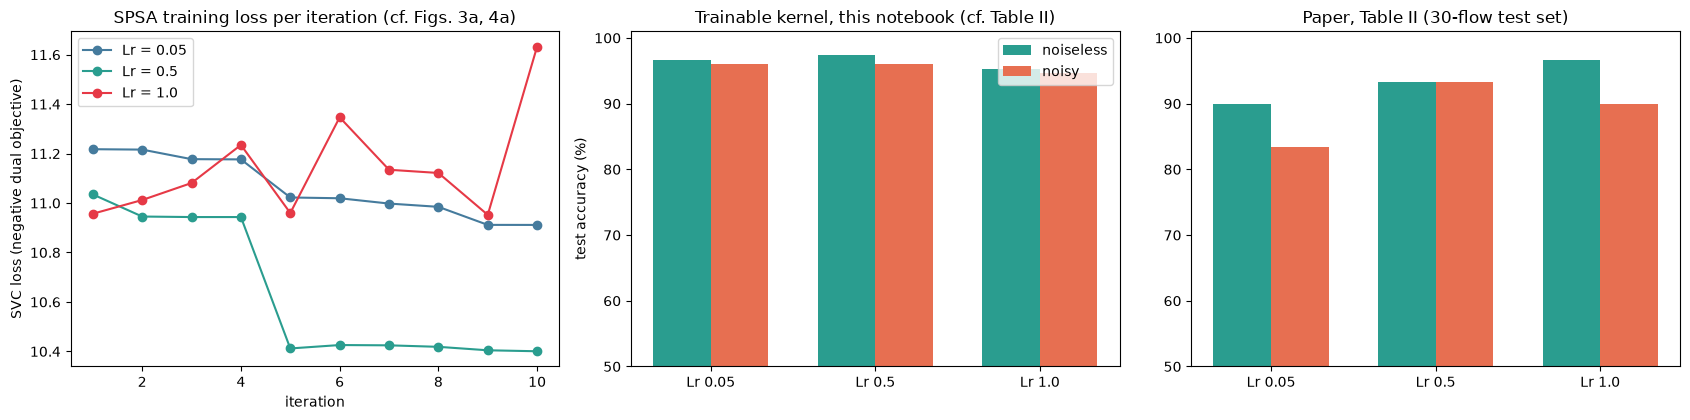

In [22]:
t2 = T2.groupby("lr").agg(noiseless=("noiseless", "mean"), noiseless_std=("noiseless", "std"), noisy=("noisy", "mean"), noisy_std=("noisy", "std"),
                           chunk30_sd_noiseless=("chunk30_sd_noiseless", "mean"), chunk30_sd_noisy=("chunk30_sd_noisy", "mean"), untrained=("untrained", "mean"), final_loss=("final_loss", "mean"))
t2["noise_penalty"] = t2.noiseless - t2.noisy
print("Table II re-computed (mean over seeds, test accuracy in %):"); print(t2.fillna(0).round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
cols = {0.05: "#457b9d", 0.5: "#2a9d8f", 1.0: "#e63946"}
for lr in SPSA_LRS:
    H = np.array([LOSSES[(s, lr)] for s in SEEDS if len(LOSSES[(s, lr)]) == SPSA_MAXITER])
    if len(H):
        x = np.arange(1, H.shape[1] + 1)
        axes[0].plot(x, H.mean(0), "-o", color=cols[lr], label=f"Lr = {lr}")
        if len(H) > 1: axes[0].fill_between(x, H.mean(0) - H.std(0), H.mean(0) + H.std(0), color=cols[lr], alpha=0.2)
axes[0].set_title("SPSA training loss per iteration (cf. Figs. 3a, 4a)"); axes[0].set_xlabel("iteration"); axes[0].set_ylabel("SVC loss (negative dual objective)"); axes[0].legend()
w = 0.35; xs = np.arange(len(SPSA_LRS))
axes[1].bar(xs - w/2, t2.noiseless, w, label="noiseless", color="#2a9d8f"); axes[1].bar(xs + w/2, t2.noisy, w, label="noisy", color="#e76f51")
axes[1].set_xticks(xs); axes[1].set_xticklabels([f"Lr {lr}" for lr in SPSA_LRS]); axes[1].set_ylim(50, 101); axes[1].set_ylabel("test accuracy (%)"); axes[1].set_title("Trainable kernel, this notebook (cf. Table II)"); axes[1].legend()
paper_t2 = {"noiseless": [90.00, 93.33, 96.67], "noisy": [83.33, 93.33, 90.00]}
axes[2].bar(xs - w/2, paper_t2["noiseless"], w, color="#2a9d8f"); axes[2].bar(xs + w/2, paper_t2["noisy"], w, color="#e76f51")
axes[2].set_xticks(xs); axes[2].set_xticklabels([f"Lr {lr}" for lr in SPSA_LRS]); axes[2].set_ylim(50, 101); axes[2].set_title("Paper, Table II (30-flow test set)")
plt.tight_layout(); plt.show()

## 10. Confusion matrices and where the errors are

Left: 8-qubit QSVC (Table I settings) on the first seed's test split; right: trainable kernel with Lr = 0.5. Attack is the positive class. Below, the share of test flows of each family that was classified correctly.

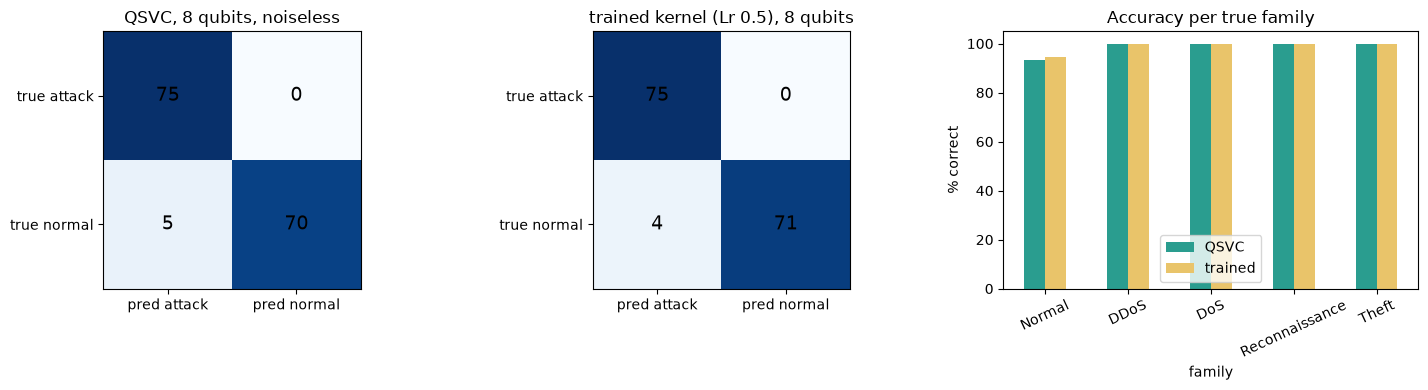

                 QSVC  trained
family                        
Normal           93.3     94.7
DDoS            100.0    100.0
DoS             100.0    100.0
Reconnaissance  100.0    100.0
Theft           100.0    100.0
QSVC:    {'acc': 0.967, 'prec': 0.938, 'rec': 1.0, 'f1': 0.968}
trained: {'acc': 0.973, 'prec': 0.949, 'rec': 1.0, 'f1': 0.974}


In [23]:
yte0, cte0 = KEEP["yte"], KEEP["cte"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pr) in zip(axes[:2], [("QSVC, %d qubits, noiseless" % QUBITS[0], KEEP["pred"]), ("trained kernel (Lr 0.5), 8 qubits", KEEP["tr_pred"])]):
    cm = confusion_matrix(yte0, pr, labels=[1, 0]); ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred attack", "pred normal"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true attack", "true normal"]); ax.set_title(name)
fam = pd.DataFrame({"family": cte0, "QSVC": KEEP["pred"] == yte0, "trained": KEEP["tr_pred"] == yte0}).groupby("family")[["QSVC", "trained"]].mean().reindex(CAT_ORDER) * 100
fam.plot.bar(ax=axes[2], color=["#2a9d8f", "#e9c46a"]); axes[2].set_ylabel("% correct"); axes[2].set_ylim(0, 105); axes[2].set_title("Accuracy per true family"); axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()
print(fam.round(1).to_string())
print("QSVC:   ", {k: round(v, 3) for k, v in metrics(yte0, KEEP['pred']).items()})
print("trained:", {k: round(v, 3) for k, v in metrics(yte0, KEEP['tr_pred']).items()})

## 11. Side-by-side comparison with the paper

Verdict rule: a claim is *reproduced* when the notebook's mean test accuracy is within 2 accuracy points of the paper's value, *not reached* when it is lower by more, *exceeded* when it is higher by more. Note the size of the paper's own
test set: Table II accuracies are multiples of 1/30, so a single flow is 3.3 points and the binomial standard error of a 30-flow accuracy near 90 % is about 5 points.

In [24]:
def fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)): return "-"
    if isinstance(v, str): return v
    return f"{v:.2e}" if (v != 0 and abs(v) < 0.01) else f"{v:.2f}"

def verdict(paper, nb, tol=2.0):
    if nb is None or (isinstance(nb, float) and np.isnan(nb)): return "cannot be checked / not run in this mode"
    return "reproduced" if abs(nb - paper) <= tol else ("exceeded (+%.1f)" % (nb - paper) if nb > paper else "not reached (%.1f)" % (nb - paper))

rows = []
paper_t1 = {8: (86.67, 83.67), 10: (83.33, 76.67), 12: (83.33, 76.67), 15: (86.67, 76.67)}
t1m = T1.groupby("qubits")[["noiseless", "noisy"]].mean()
for Q, (pn, py) in paper_t1.items():
    a = t1m.noiseless.get(Q, np.nan); b = t1m.noisy.get(Q, np.nan)
    rows.append(dict(claim=f"Table I, {Q} qubits, QSVC noiseless", paper=pn, notebook=a, verdict=verdict(pn, a)))
    rows.append(dict(claim=f"Table I, {Q} qubits, QSVC noisy", paper=py, notebook=b, verdict=verdict(py, b)))
for lr, pn, py in [(0.05, 90.00, 83.33), (0.5, 93.33, 93.33), (1.0, 96.67, 90.00)]:
    rows.append(dict(claim=f"Table II, Lr={lr}, trainable kernel noiseless", paper=pn, notebook=t2.noiseless[lr], verdict=verdict(pn, t2.noiseless[lr])))
    rows.append(dict(claim=f"Table II, Lr={lr}, trainable kernel noisy", paper=py, notebook=t2.noisy[lr], verdict=verdict(py, t2.noisy[lr])))
svc_acc = float(T1.groupby("qubits").acc_SVC_rbf.mean().get(8, np.nan)); best_q = float(T2.groupby("lr").noiseless.mean().max())
rows.append(dict(claim="Classical SVC on identical data reaches only 70 %", paper=70.0, notebook=svc_acc, verdict="not reached: the classical SVC here is far stronger than 70 %" if svc_acc > 72 else "reproduced"))
rows.append(dict(claim="Quantum advantage of 26.67 points over the classical SVC", paper=26.67, notebook=best_q - svc_acc, verdict="not reached: no advantage over the classical SVC" if best_q - svc_acc < 21.67 else "reproduced"))
rows.append(dict(claim="QWPT circuit vs classical Haar: mean l2 error < 1e-6", paper="< 1e-6", notebook=QWPT_L2_ERROR, verdict="reproduced" if QWPT_L2_ERROR < 1e-6 else "not reached"))
d15, d8 = (t1m.noiseless - t1m.noisy).get(max(QUBITS), np.nan), (t1m.noiseless - t1m.noisy).get(8, np.nan)
rows.append(dict(claim=f"Noise hurts large circuits more (drop at {max(QUBITS)} qubits > drop at 8)", paper="~10 vs ~3 pts", notebook=f"{d15:.1f} vs {d8:.1f} pts", verdict="reproduced" if d15 > d8 + 1 else "not reached"))
pen = (t2.noiseless - t2.noisy)
rows.append(dict(claim="Lr = 0.5 gives the smallest noise penalty (paper: 6.7 / 0.0 / 6.7 points at Lr 0.05 / 0.5 / 1.0)", paper="min at 0.5", notebook=f"min at {pen.idxmin()} ({', '.join(f'{k}: {v:.1f}' for k, v in pen.items())})", verdict="reproduced" if pen.idxmin() == 0.5 else "not reached"))
rows.append(dict(claim="Lr = 0.5 gives the most stable (lowest final) SPSA loss", paper="Fig. 3a", notebook=f"lowest final loss at Lr {t2.final_loss.idxmin()}", verdict="reproduced" if t2.final_loss.idxmin() == 0.5 else "not reached"))
rows.append(dict(claim="89.67 % on IoT-23 (> 82.53 % of Hdaib et al.)", paper=89.67, notebook=None, verdict="cannot be checked (no IoT-23 configuration in the paper; not run)"))
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 220, "display.max_colwidth", 95)
CMP_show = CMP.copy(); CMP_show["paper"] = CMP.paper.map(fmt); CMP_show["notebook"] = CMP.notebook.map(fmt)
print(CMP_show.to_string(index=False))
print("\nverdict counts:", CMP.verdict.str.split(" ").str[0].value_counts().to_dict())

                                                                                           claim         paper                                    notebook                                                           verdict
                                                               Table I, 8 qubits, QSVC noiseless         86.67                                       96.67                                                  exceeded (+10.0)
                                                                   Table I, 8 qubits, QSVC noisy         83.67                                       96.00                                                  exceeded (+12.3)
                                                              Table I, 10 qubits, QSVC noiseless         83.33                                       97.33                                                  exceeded (+14.0)
                                                                  Table I, 10 qubits, QSVC noisy         76.67      

## Reading the paper critically

* **The data are easy.** On the public BoT-IoT mirror, every classical model reaches 93-100 % on the same inputs. The paper's "classical SVC = 70 %" cannot be reproduced with an ordinary RBF-SVC; the quantum model
  does not beat a properly set up classical baseline here, so the "26.67 points of quantum advantage" is a statement about a weak baseline, not about quantum computing. The headline "conclusively proves quantum advantage" is not supported by the evidence in the paper.
* **Tiny test sets.** Table II accuracies are multiples of 1/30; differences of 3.3 points between learning rates are one flow. The "moderate learning rate is best" conclusion rests on single runs.
* **Unspecified experiment.** Sample size, features, split, `C`, noise strengths, number of shots and qubit count of the trainable kernel are not given, nor is it clear whether noise is present during training. Figures 3-9 describe training and test *loss* but the test loss is not defined for an SVC.
* **"Quantum" wavelet transform.** Algorithm 2 prepares a product state with one `RY` per feature, applies a CX/H/RZ ladder and reads out all `2^n` probabilities. This needs `2^n` shots to resolve the distribution and gives a data-dependent but not an exact Haar packet transform; the exact Haar transform of an amplitude vector is just Hadamards on the low qubits, as the check above shows. The actual wavelet-packet energies are computed classically in this notebook.
* **Noise.** Qiskit's depolarizing model for more than 12 qubits cannot be simulated exactly with a density matrix; the paper does not say how it did it. The noisy columns here use an analytic approximation of the depolarizing noise (a global damping plus shot noise) whose error against Aer is shown in Section 8; it is a plausible stand-in, not the paper's unspecified noise model.
* **Eqs. 1-3 and 12-13** (weighted hinge loss, one-class QSVM, composite RBF/quantum kernel) have no experiments; they are not part of the reported results.
* **Dataset.** The mirror is a *balanced* variant of Bot-IoT built by a third party, not the original CSV files; flows of the same attack run are strongly correlated, so a random split overestimates real-world performance.

## Exercises

1. Change `N_WAVELET_QUBITS` to 6 or 10 and rerun Table I. How does the number of wavelet-packet coefficients change, and does accuracy follow?
2. Replace the paper's QWPT features by the 8 raw selected features (`kind="raw8"`) in Table I and compare noiseless and noisy accuracy. Does the wavelet step help at all?
3. Increase the noise (`P2Q = 0.03`) and find the qubit count at which the QSVC becomes worse than the random forest. Why does the kernel off-diagonal mean (column `kernel_offdiag_mean`) matter?
4. Implement the composite kernel of Eq. 13, `alpha K_rbf + (1-alpha) K_quantum`, and sweep `alpha`. Does a classical kernel in the mix remove the noise sensitivity?
5. Group the split by attack run instead of at random (for example by `stime`-based blocks) to reduce leakage between train and test. How much accuracy remains?